In [1]:
!pip -q install mne scipy scikit-learn pandas matplotlib tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [2]:
import os, time, random, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import mne
from mne.datasets import eegbci
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

Device: cuda


In [3]:
# Dataset configuration

SUBJECTS = list(range(1, 11))

RUNS = [4, 8, 12]

SFREQ = 160

WINDOW_SECONDS = 1.0
WINDOW_SAMPLES = int(SFREQ * WINDOW_SECONDS)

STRIDE_SECONDS = 0.5
STRIDE = int(SFREQ * STRIDE_SECONDS)

LOW_CHANNELS = 16
HIGH_CHANNELS = 64

BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-3

print("Dataset settings configured successfully!")
print("Number of subjects:", len(SUBJECTS))
print("EEG sampling rate:", SFREQ)
print("Low-resolution channels:", LOW_CHANNELS)
print("High-resolution channels:", HIGH_CHANNELS)

Dataset settings configured successfully!
Number of subjects: 10
EEG sampling rate: 160
Low-resolution channels: 16
High-resolution channels: 64


In [4]:
def load_subject_windows(subject):

    files = eegbci.load_data(subject, RUNS, update_path=True)

    subject_windows = []

    for f in files:

        raw = mne.io.read_raw_edf(
            f, preload=True, verbose="ERROR"
        )

        raw.rename_channels(lambda x: x.strip("."))

        raw.pick_types(eeg=True, exclude=[])

        raw.filter(
            0.5, 40.0,
            fir_design="firwin",
            verbose="ERROR"
        )

        if int(round(raw.info["sfreq"])) != SFREQ:
            raw.resample(SFREQ, npad="auto", verbose="ERROR")

        data = raw.get_data()

        if data.shape[0] < HIGH_CHANNELS:
            continue

        data = data[:HIGH_CHANNELS]

        for start in range(
            0,
            data.shape[1] - WINDOW_SAMPLES + 1,
            STRIDE
        ):

            w = data[:, start:start + WINDOW_SAMPLES].astype(np.float32)

            if np.isfinite(w).all():
                subject_windows.append(w)

    return subject_windows


all_windows = []

for sid in tqdm(SUBJECTS, desc="Downloading/processing subjects"):

    try:
        all_windows.extend(load_subject_windows(sid))

    except Exception as e:
        print(f"Subject {sid} skipped: {e}")


X = (
    np.stack(all_windows)
    if all_windows
    else np.empty((0, HIGH_CHANNELS, WINDOW_SAMPLES), dtype=np.float32)
)

print("Window tensor:", X.shape, "(windows, channels, samples)")

assert len(X) > 10, "No/too few windows loaded. Check dataset download and MNE output."

Downloading/processing subjects:   0%|          | 0/10 [00:00<?, ?it/s]

Using default location ~/mne_data for EEGBCI...
Creating /root/mne_data


Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 03s (7.4 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.3 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.4 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.3 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


... (2 outputs left out)

Download complete in 03s (7.4 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.3 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.3 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


Download complete in 03s (7.3 MB)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Window tensor: (7386, 64, 160) (windows, channels, samples)


Number of windows: 7386
Number of target channels: 64
Samples per window: 160
Sampling rate: 160 Hz
Approx. duration represented (hours): 2.0516666666666667


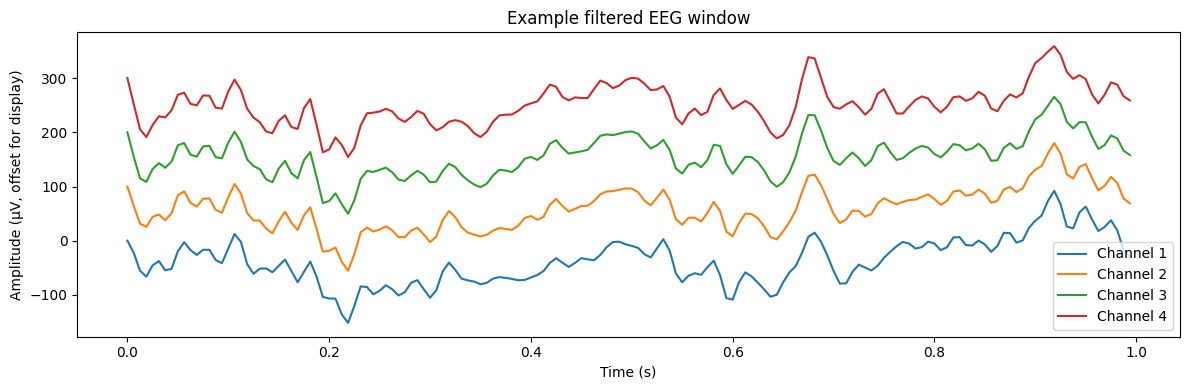

In [5]:
print("Number of windows:", len(X))
print("Number of target channels:", X.shape[1])
print("Samples per window:", X.shape[2])
print("Sampling rate:", SFREQ, "Hz")

print(
    "Approx. duration represented (hours):",
    len(X) * WINDOW_SECONDS / 3600
)

plt.figure(figsize=(12, 4))

t = np.arange(WINDOW_SAMPLES) / SFREQ

for ch in range(4):
    plt.plot(
        t,
        X[0, ch] * 1e6 + ch * 100,
        label=f"Channel {ch+1}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV, offset for display)")
plt.title("Example filtered EEG window")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
low_idx = np.linspace(
    0, HIGH_CHANNELS - 1,
    LOW_CHANNELS,
    dtype=int
)

X_low = X[:, low_idx, :]

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X_low, X,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp,
    test_size=2/3,
    random_state=SEED,
    shuffle=True
)

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

print("Low-resolution channel indices:", low_idx.tolist())

Train: (5170, 16, 160) (5170, 64, 160)
Validation: (738, 16, 160) (738, 64, 160)
Test: (1478, 16, 160) (1478, 64, 160)
Low-resolution channel indices: [0, 4, 8, 12, 16, 21, 25, 29, 33, 37, 42, 46, 50, 54, 58, 63]


In [7]:
mean = Y_train.mean()
std = Y_train.std() + 1e-8

def norm(a):
    return ((a - mean) / std).astype(np.float32)


X_train_n, Y_train_n = norm(X_train), norm(Y_train)
X_val_n, Y_val_n = norm(X_val), norm(Y_val)
X_test_n, Y_test_n = norm(X_test), norm(Y_test)


class EEGDataset(Dataset):

    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


train_loader = DataLoader(
    EEGDataset(X_train_n, Y_train_n),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    EEGDataset(X_val_n, Y_val_n),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    EEGDataset(X_test_n, Y_test_n),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Normalization and DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Normalization and DataLoaders created successfully!
Training batches: 324
Validation batches: 47
Testing batches: 93


In [8]:
class DirectionalSSM2D(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)
        self.norm = nn.BatchNorm2d(channels)

    def forward(self, x):
        x = self.proj(x)
        x = torch.relu(self.norm(x))
        return x


class ChannelAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // 4, 1),
            nn.ReLU(),
            nn.Conv2d(channels // 4, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(self.pool(x))


class EMambaBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.ssm = DirectionalSSM2D(channels)
        self.attention = ChannelAttention(channels)

    def forward(self, x):
        return x + self.attention(self.ssm(x))


class MASERBaseline(nn.Module):
    def __init__(self, low_channels=16, high_channels=64):
        super().__init__()

        self.input_projection = nn.Conv2d(
            1, 32, kernel_size=3, padding=1
        )

        self.blocks = nn.Sequential(
            EMambaBlock(32),
            EMambaBlock(32),
            EMambaBlock(32)
        )

        self.output_projection = nn.Conv2d(
            32, 1, kernel_size=3, padding=1
        )

        self.channel_expansion = nn.Linear(
            low_channels, high_channels
        )

    def forward(self, x):
        x = self.channel_expansion(x.transpose(1, 2))
        x = x.transpose(1, 2)

        x = x.unsqueeze(1)
        x = self.input_projection(x)
        x = self.blocks(x)
        x = self.output_projection(x)

        return x.squeeze(1)


model = MASERBaseline(
    low_channels=LOW_CHANNELS,
    high_channels=HIGH_CHANNELS
).to(DEVICE)

print(model)
print("\nModel created successfully!")

MASERBaseline(
  (input_projection): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (blocks): Sequential(
    (0): EMambaBlock(
      (ssm): DirectionalSSM2D(
        (proj): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (attention): ChannelAttention(
        (pool): AdaptiveAvgPool2d(output_size=1)
        (fc): Sequential(
          (0): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (1): ReLU()
          (2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (3): Sigmoid()
        )
      )
    )
    (1): EMambaBlock(
      (ssm): DirectionalSSM2D(
        (proj): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (attention): ChannelAttention(
        (pool): AdaptiveAvgPool2d(output_size=1)
        (

In [9]:
ALPHA = 0.001
BETA = 1e-5

def total_loss(pred, target, model):

    mse = nn.functional.mse_loss(pred, target)

    smoothness = torch.mean(
        (pred[:, :, 1:] - pred[:, :, :-1]) ** 2
    )

    l2 = sum(
        torch.sum(param ** 2)
        for param in model.parameters()
    )

    loss = mse + ALPHA * smoothness + BETA * l2

    return loss, mse, smoothness


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function and optimizer configured successfully!")

Loss function and optimizer configured successfully!


In [10]:
history = {
    "train_loss": [],
    "val_loss": []
}

start_time = time.time()

for epoch in range(EPOCHS):

    model.train()
    train_losses = []

    for xb, yb in train_loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        pred = model(xb)

        loss, _, _ = total_loss(pred, yb, model)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    model.eval()
    val_losses = []

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            pred = model(xb)

            loss, _, _ = total_loss(pred, yb, model)

            val_losses.append(loss.item())

    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Validation Loss: {val_loss:.6f}"
    )

training_time = time.time() - start_time

print("\nTraining completed!")
print("Training time:", round(training_time, 2), "seconds")

Epoch [1/20] Train Loss: 0.374987 Validation Loss: 0.229682
Epoch [2/20] Train Loss: 0.216259 Validation Loss: 0.194856
Epoch [3/20] Train Loss: 0.193702 Validation Loss: 0.182446
Epoch [4/20] Train Loss: 0.182042 Validation Loss: 0.173230
Epoch [5/20] Train Loss: 0.175858 Validation Loss: 0.168093
Epoch [6/20] Train Loss: 0.171844 Validation Loss: 0.169171
Epoch [7/20] Train Loss: 0.168520 Validation Loss: 0.162032
Epoch [8/20] Train Loss: 0.165899 Validation Loss: 0.162946
Epoch [9/20] Train Loss: 0.164044 Validation Loss: 0.160806
Epoch [10/20] Train Loss: 0.161410 Validation Loss: 0.156107
Epoch [11/20] Train Loss: 0.160893 Validation Loss: 0.159389
Epoch [12/20] Train Loss: 0.159314 Validation Loss: 0.154489
Epoch [13/20] Train Loss: 0.157363 Validation Loss: 0.153634
Epoch [14/20] Train Loss: 0.156629 Validation Loss: 0.156110
Epoch [15/20] Train Loss: 0.156281 Validation Loss: 0.153452
Epoch [16/20] Train Loss: 0.155865 Validation Loss: 0.151216
Epoch [17/20] Train Loss: 0.15489

In [11]:
import torch
import matplotlib.pyplot as plt
import time

print("Completed Epochs:", len(history["train_loss"]))

torch.save(model.state_dict(), "/content/MASER_baseline.pth")

print("Model saved successfully!")

Completed Epochs: 20
Model saved successfully!


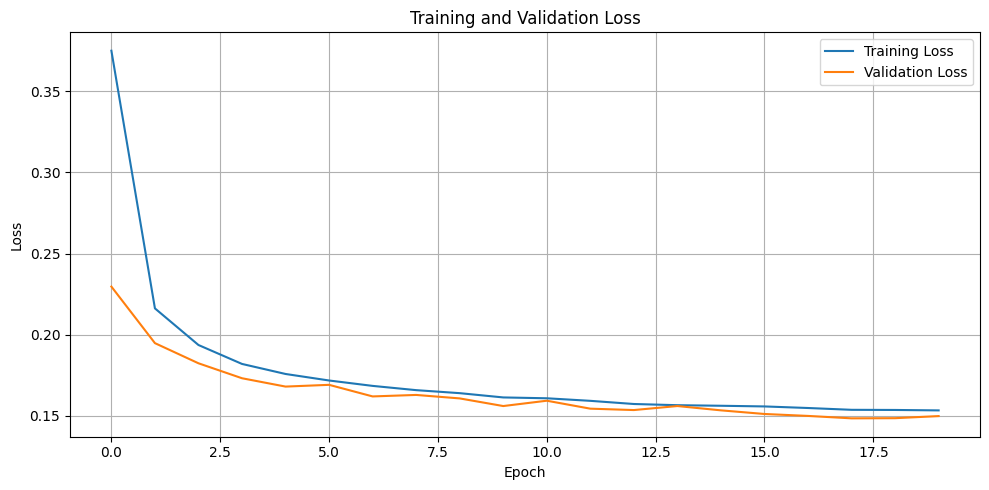

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
print("Training Configuration")
print("----------------------")
print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Input Channels:", LOW_CHANNELS)
print("Output Channels:", HIGH_CHANNELS)

print("\nTraining Time:", round(training_time, 2), "seconds")
print("Completed Epochs:", len(history["train_loss"]))

Training Configuration
----------------------
Device: cuda
Epochs: 20
Batch Size: 16
Learning Rate: 0.001
Optimizer: Adam
Input Channels: 16
Output Channels: 64

Training Time: 133.46 seconds
Completed Epochs: 20


In [14]:
import json

results = {
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam"
}

with open("/content/training_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Training history saved successfully!")

Training history saved successfully!


In [15]:
from google.colab import files

files.download("/content/MASER_baseline.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
files.download("/content/training_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
print("Model available:", "model" in globals())
print("Test loader available:", "test_loader" in globals())
print("Device available:", "DEVICE" in globals())
print("Test samples:", len(test_loader.dataset) if "test_loader" in globals() else "Not available")

Model available: True
Test loader available: True
Device available: True
Test samples: 1478


In [18]:
import numpy as np
import torch

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        predictions = model(xb)

        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(yb.numpy())

y_pred = np.concatenate(all_predictions, axis=0)
y_true = np.concatenate(all_targets, axis=0)

mse = np.mean((y_true - y_pred) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_true - y_pred))

nmse = mse / (np.mean(y_true ** 2) + 1e-8)

pcc = np.corrcoef(y_true.flatten(), y_pred.flatten())[0, 1]

print("Test Evaluation Results")
print("-----------------------")
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("nMSE:", nmse)
print("PCC:", pcc)
print("Test samples evaluated:", len(y_true))

Test Evaluation Results
-----------------------
MSE: 0.15363823
RMSE: 0.39196712
MAE: 0.21130483
nMSE: 0.14994153
PCC: 0.9223662901407614
Test samples evaluated: 1478


In [19]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["nMSE", "PCC"],
    "Original Paper": [0.146, 0.922],
    "Reproduced Model": [nmse, pcc],
    "Difference": [nmse - 0.146, pcc - 0.922]
})

display(comparison.round(6))

,Metric,Original Paper,Reproduced Model,Difference
0,nMSE,0.146,0.149942,0.003942
1,PCC,0.922,0.922366,0.000366
